In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [12]:
# 1.1 Loading the data:
def load_data():
    #df = pd.read_csv("/content/drive/MyDrive/P1_dataset/day.csv")
    df = pd.read_csv("/Users/keeney/desktop/bike+sharing+dataset/day.csv")
    return df


#Inspect the dataset structure: number of samples and features, feature names, data types.
def basic_overview(df: pd.DataFrame, target: str = "cnt") -> None:
    print("Shape:", df.shape)
    print("Columns:", list(df.columns))

    print("\nHead:")
    print(df.head(5))

    print("\nInfo:")
    print(df.info())

    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found in columns!")

    print(f"\nTarget '{target}' summary:")
    print(df[target].describe())

In [13]:
# 1.2 Cleaning and preprocessing to produce:
"""
    X_processed: numeric model matrix (scaled numeric + one-hot categoricals)
    y: target vector

  Requirements covered:
    - missing or malformed handling
    - drop identifier columns
    - avoid leakage
    - one-hot encode categoricals
    - scale numeric features (standardization)
"""
def preprocess(df_raw, target="cnt"):
    df = df_raw.copy()

    # Missing or malformed values:
    # Replace common placeholders with NaN.
    df = df.replace(["?", "NA", "N/A", "null", "None", ""], np.nan)

    # Drop raw date string column: we are droping this because it
    # linear regression only expects numeric features with meaningful distances.
    if "dteday" in df.columns:
        df = df.drop(columns=["dteday"])

    # Print what's missing.
    print("Missing counts (before handling):")
    print(df.isna().sum())
    print()

    # If missing exists, we choose to impute:
    # For missing numerical value we use median.
    # For missing categorical value we use mode.
    for c in df.columns:
        if df[c].isna().any():
            if pd.api.types.is_numeric_dtype(df[c]):
                df[c] = df[c].fillna(df[c].median())
            else:
                df[c] = df[c].fillna(df[c].mode(dropna=True).iloc[0])

    # Drop identifier / irrelevant features:
    if "instant" in df.columns:
        df = df.drop(columns=["instant"])

    # Avoid leakage:
    # cnt = casual + registered, so casual/registered leak the target
    for leak in ["casual", "registered"]:
        if leak in df.columns:
            df = df.drop(columns=[leak])

    # Split X / y:
    # Y only contains cnt
    # X is all the remaining features:
    if target not in df.columns:
        raise ValueError(f"Target '{target}' not found after cleaning.")
    y = df[target].copy()
    X = df.drop(columns=[target])

    # Categorical handling (one-hot):
    # These are discrete code columns in day.csv
    cat_cols = [c for c in ["season", "yr", "mnth", "holiday", "weekday", "workingday", "weathersit"]
                if c in X.columns]
    num_cols = [c for c in X.columns if c not in cat_cols]

    # Converts each categorical columns into multiple binary columns
    # For example: season with values {1,2,3,4} becomes season_01, season_02, season_03, season_04 each with value 0 / 1
    X_cat = pd.get_dummies(X[cat_cols].astype("category"), drop_first=False) if cat_cols else pd.DataFrame(index=X.index)
    X_num = X[num_cols].copy()

    # Feature scaling (standardization):
    # (x - mean) / std, computed on current data
    if len(num_cols) > 0:
        mean = X_num.mean()
        std = X_num.std(ddof=0).replace(0, 1e-12)
        X_num = (X_num - mean) / std

    # Final design matrix
    X_processed = pd.concat([X_num, X_cat], axis=1)

    # Some info useful for debugging / report
    info = {
        "categorical_cols_onehot": cat_cols,
        "numeric_cols_scaled": num_cols,
        "final_num_features": X_processed.shape[1],
        "rows": X_processed.shape[0],
    }
    return X_processed, y, info


In [14]:
#1.3 Make plots to understand distributions, outliers, and relationships.

def eda_plots(df_raw, target="cnt"):
    df = df_raw.copy()

    # Distribution of target
    plt.figure()
    plt.hist(df[target], bins=30)
    plt.title(f"Target distribution: {target}")
    plt.xlabel(target)
    plt.ylabel("count")
    plt.show()

    # Histograms of some numeric features (present in day.csv)
    for c in ["temp", "atemp", "hum", "windspeed"]:
        if c in df.columns:
            plt.figure()
            plt.hist(df[c], bins=30)
            plt.title(f"Histogram: {c}")
            plt.xlabel(c)
            plt.ylabel("count")
            plt.show()

    # Scatter plots vs target
    for c in ["temp", "atemp", "hum", "windspeed"]:
        if c in df.columns:
            plt.figure()
            plt.scatter(df[c], df[target], s=10)
            plt.title(f"{c} vs {target}")
            plt.xlabel(c)
            plt.ylabel(target)
            plt.show()

    # Boxplots
    for c in ["temp", "atemp", "hum", "windspeed", target]:
        if c in df.columns:
            plt.figure()
            plt.boxplot(df[c].dropna(), vert=True)
            plt.title(f"Boxplot: {c}")
            plt.ylabel(c)
            plt.show()


Shape: (731, 16)
Columns: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']

Head:
   instant      dteday  season  yr  mnth  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1        0        6           0   
1        2  2011-01-02       1   0     1        0        0           0   
2        3  2011-01-03       1   0     1        0        1           1   
3        4  2011-01-04       1   0     1        0        2           1   
4        5  2011-01-05       1   0     1        0        3           1   

   weathersit      temp     atemp       hum  windspeed  casual  registered  \
0           2  0.344167  0.363625  0.805833   0.160446     331         654   
1           2  0.363478  0.353739  0.696087   0.248539     131         670   
2           1  0.196364  0.189405  0.437273   0.248309     120        1229   
3           1  0.200000  0.212122  0.590435   

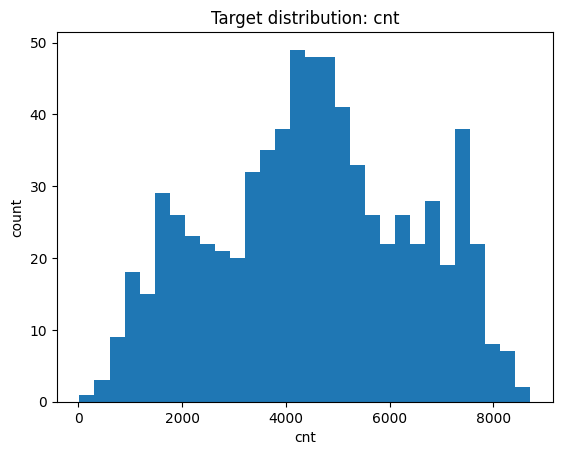

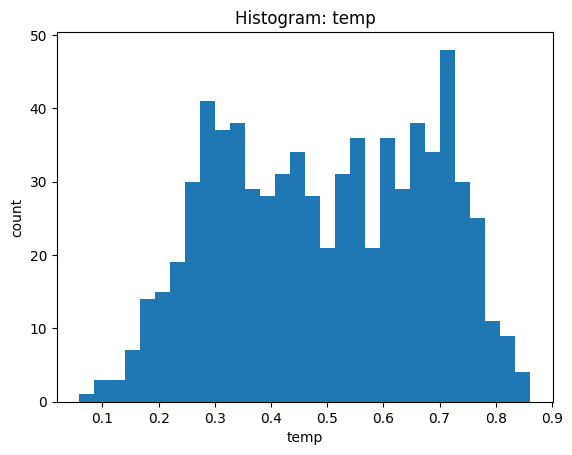

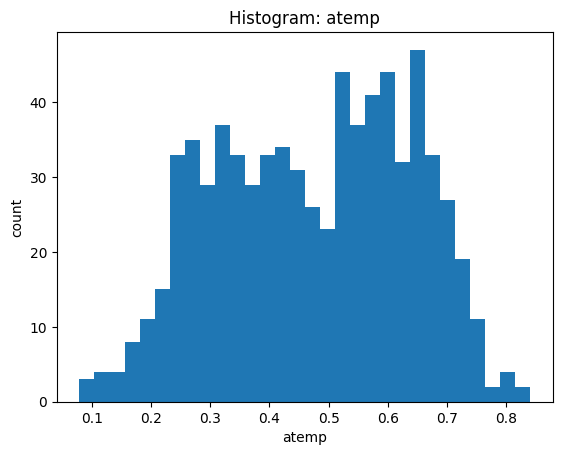

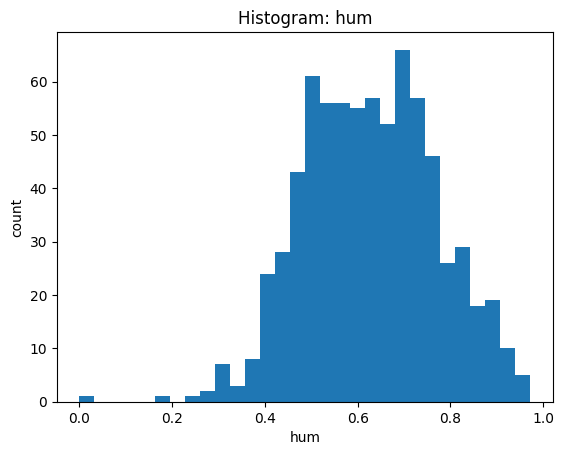

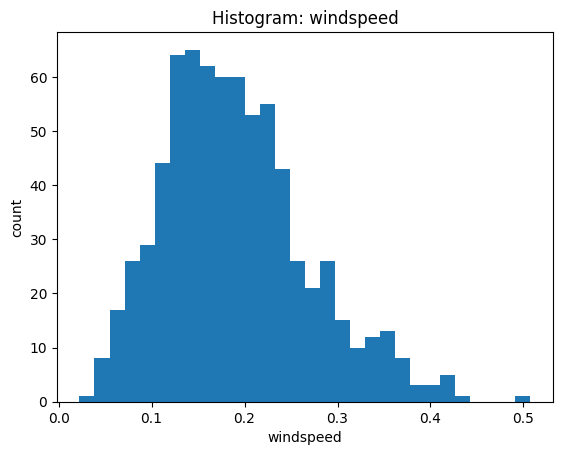

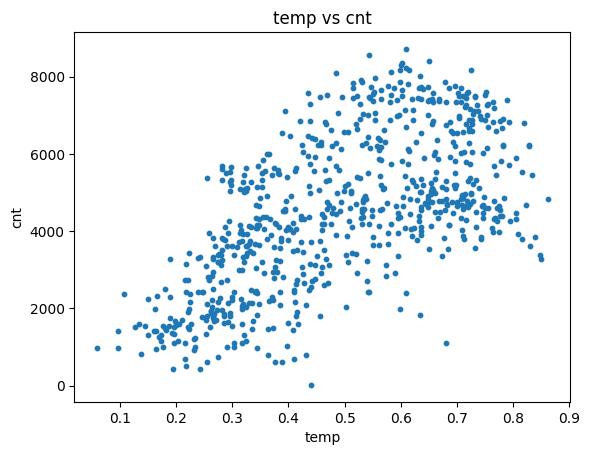

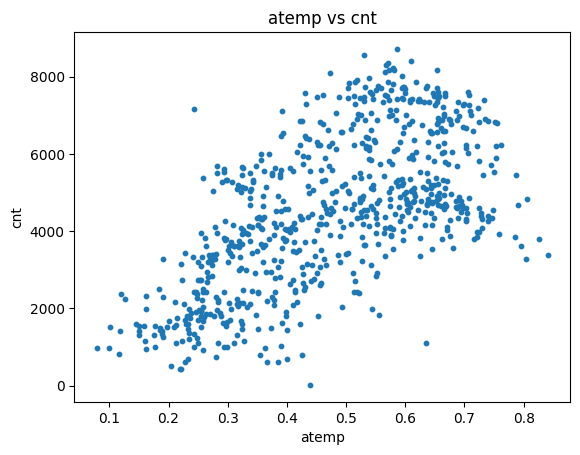

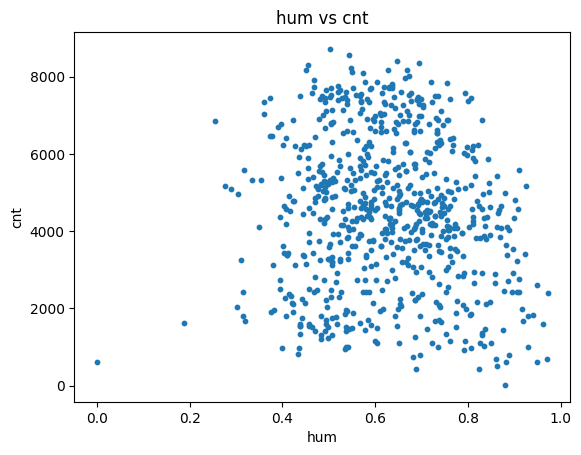

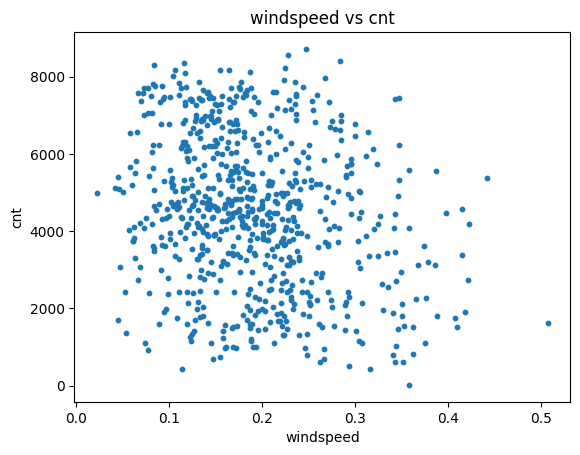

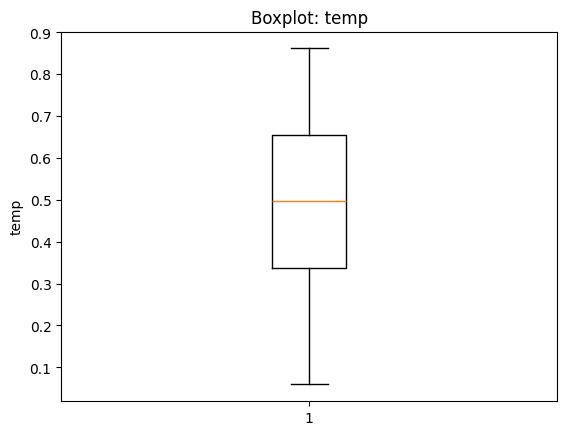

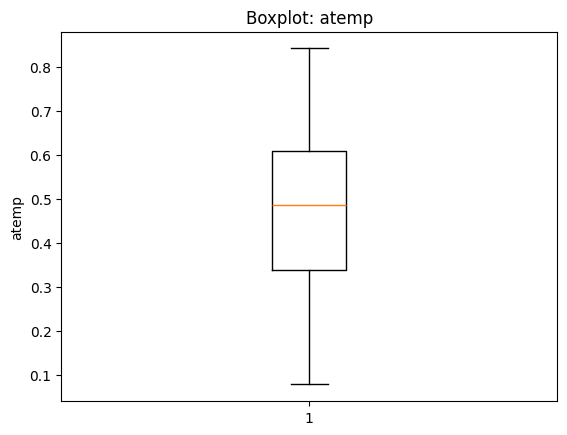

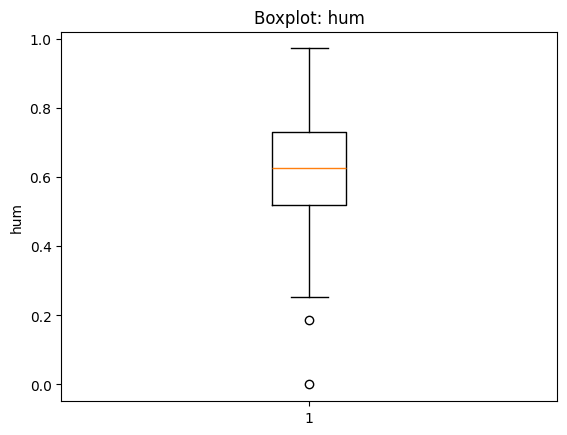

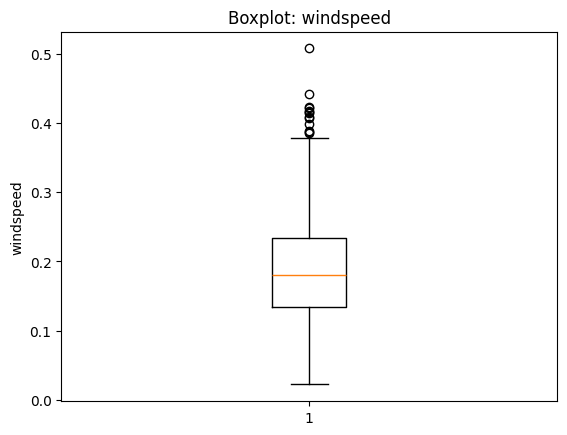

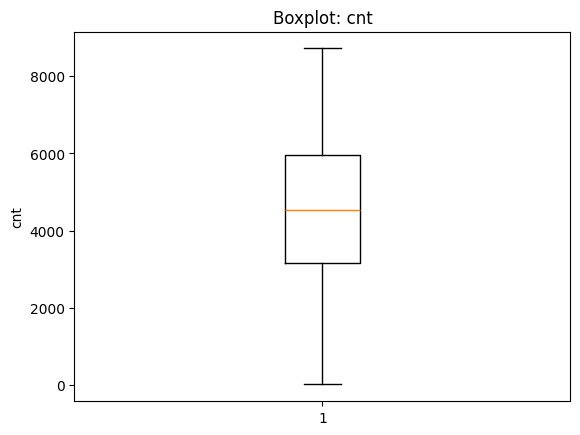

"\nExtra specification: for day.csv, there is no actual missing value,\nso it's normal to see Missing counts to be all 0.\n"

In [15]:
df_raw = load_data()        # 1.1
basic_overview(df_raw, "cnt")         # 1.1
X, y, info = preprocess(df_raw)      # 1.2
print(info)
#For 1.3, we use raw data because it helps us to potential features for part 1.2
eda_plots(df_raw, "cnt")             # 1.3

"""
Extra specification: for day.csv, there is no actual missing value,
so it's normal to see Missing counts to be all 0.
"""

In [16]:

# 2.1 Linear regression model implementation
class LinearRegression:
    def __init__(self, add_bias=True):
        self.add_bias = add_bias
        self.weights = None

    def fit(self, X, y):
        # if x 1-d convert it to 2d column vector
        if X.ndim == 1:
            X = X[:, None]

        # Attach a column of ones to X for the bias if needed,
        # Then the shape of the designed matrix becomes (N, D+1)
        if self.add_bias:
            ones = np.ones((X.shape[0], 1))
            X = np.concatenate([ones, X], axis=1)

        # Compute w = (XTX)**-1 * X^T * y, but using lstsq to avoid using actual inversion
        self.weights = np.linalg.lstsq(X, y, rcond=None)[0]

    def predict(self, X):
        # Add the same column of ones for the bias
        if self.add_bias:
            ones = np.ones((X.shape[0], 1))
            X = np.concatenate([ones, X], axis=1)

        # calculate X_b * w
        Y_predicted = np.dot(X, self.weights)
        return Y_predicted



In [17]:

# 2.2 Train/test split
def train_test_split(X, y, train_test_r=0.8):
    # split the dataset, 80% for traning rest for testing
    np.random.seed(1234)
    index = np.arange(X.shape[0])
    split_idx = int(X.shape[0] * train_test_r)

    #adding random shuffle
    np.random.shuffle(index)

    train_I = index[:split_idx]
    test_I = index[split_idx:]

    return X[train_I], X[test_I], y[train_I], y[test_I]


In [18]:
# 2.3 Evaluation metric
def mean_squared_error(y, y_predicted):
    mse = np.mean((y - y_predicted) ** 2)
    return mse



Training set MSE: 2283368.114465391
Testing set MSE: 2228121.500959607

First 10 Predictions vs Actual:
Prediction: 4883.20 ～(∠・ω< )⌒★! Actual: 3644
Prediction: 5570.31 ～(∠・ω< )⌒★! Actual: 6770
Prediction: 5059.11 ～(∠・ω< )⌒★! Actual: 3659
Prediction: 6152.97 ～(∠・ω< )⌒★! Actual: 6891
Prediction: 4745.79 ～(∠・ω< )⌒★! Actual: 4486
Prediction: 5235.01 ～(∠・ω< )⌒★! Actual: 4891
Prediction: 3003.28 ～(∠・ω< )⌒★! Actual: 1749
Prediction: 3063.75 ～(∠・ω< )⌒★! Actual: 3190
Prediction: 5443.88 ～(∠・ω< )⌒★! Actual: 4549
Prediction: 4745.79 ～(∠・ω< )⌒★! Actual: 4195


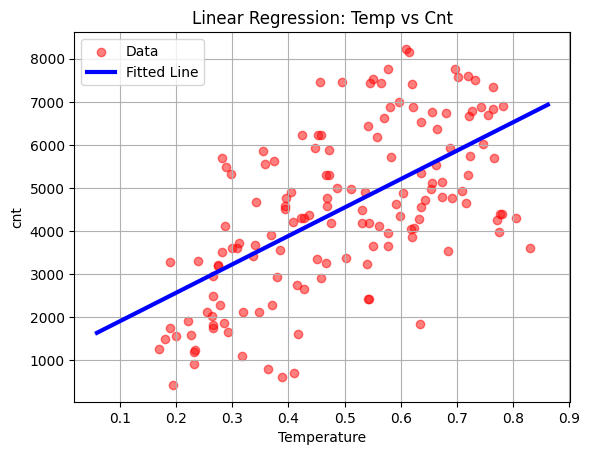

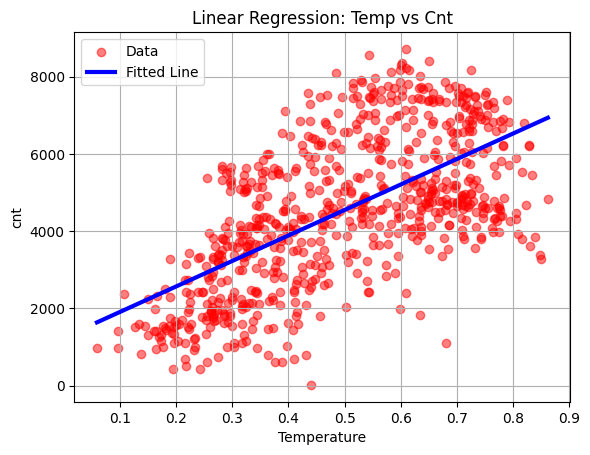

In [19]:

# Execution----------------------------------

# Load Data
#df = pd.read_csv('/content/sample_data/day.csv')
df = pd.read_csv('/Users/keeney/desktop/bike+sharing+dataset/day.csv')




features = ['temp']
x = df[features].values
y = df['cnt'].values.reshape(-1,1)

X_train, X_test, Y_train, Y_test = train_test_split(x, y)


# Train Model
model = LinearRegression()
model.fit(X_train, Y_train)

# Evaluation metric for MSE on training/testing sets
train_mse = mean_squared_error(Y_train, model.predict(X_train))
test_mse = mean_squared_error(Y_test, model.predict(X_test))

print("Training set MSE: " + str(train_mse))
print("Testing set MSE: " + str(test_mse))

print("\nFirst 10 Predictions vs Actual:")
for i in range(10):
    print(f"Prediction: {model.predict(X_test)[i][0]:.2f} ～(∠・ω< )⌒★! Actual: {Y_test[i][0]}")



# Regression Visualization
# plotting the data points, *using testing sets now
plt.scatter(X_test, Y_test, color='red', alpha=0.5, label='Data')

# Plotting the regression line
x_range = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
y_range = model.predict(x_range)

plt.plot(x_range, y_range, color='blue', linewidth=3, label='Fitted Line')
plt.title('Linear Regression: Temp vs Cnt')
plt.xlabel('Temperature')
plt.ylabel('cnt')
plt.legend()
plt.grid(True)
plt.show()

# plotting the data points, *using whole sets now
plt.scatter(x, y, color='red', alpha=0.5, label='Data')

# Plotting the regression line
x_range = np.linspace(x.min(), x.max(), 100).reshape(-1, 1)
y_range = model.predict(x_range)

plt.plot(x_range, y_range, color='blue', linewidth=3, label='Fitted Line')
plt.title('Linear Regression: Temp vs Cnt')
plt.xlabel('Temperature')
plt.ylabel('cnt')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# 3.1 Feature Engineering: Non linear features
import numpy as np
import pandas as pd

def build_engineered_features(df: pd.DataFrame,
                              base_num_cols=None,
                              add_squares=True,
                              add_interactions=True):

    if base_num_cols is None:
        # Safe numeric choices (no leakage, commonly used)
        # day.csv has: temp, atemp, hum, windspeed (all numeric)
        base_num_cols = [c for c in ["temp", "atemp", "hum", "windspeed"] if c in df.columns]

    # Extract numeric base features
    X_base = df[base_num_cols].values.astype(float)
    feature_names = base_num_cols.copy()

    X_parts = [X_base]

    # Add squared terms
    if add_squares:
        X_sq = X_base ** 2
        X_parts.append(X_sq)
        feature_names += [f"{c}^2" for c in base_num_cols]

    # Add interaction terms (pairwise products)
    if add_interactions:
        inter_cols = []
        inter_parts = []
        D = X_base.shape[1]
        for i in range(D):
            for j in range(i + 1, D):
                inter_parts.append((X_base[:, i] * X_base[:, j]).reshape(-1, 1))
                inter_cols.append(f"{base_num_cols[i]}*{base_num_cols[j]}")
        if len(inter_parts) > 0:
            X_inter = np.concatenate(inter_parts, axis=1)
            X_parts.append(X_inter)
            feature_names += inter_cols

    # Final engineered feature matrix
    X_eng = np.concatenate(X_parts, axis=1)

    return X_eng, feature_names


def standardize_train_test(X_train, X_test):
    """
    Standardize using train statistics ONLY (important! no leakage).
    """
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0, ddof=0)
    std[std == 0] = 1e-12

    X_train_s = (X_train - mean) / std
    X_test_s = (X_test - mean) / std
    return X_train_s, X_test_s

# ---------- Run Task 3.1 experiment ----------
# Load data (use your own path)
df = pd.read_csv("/Users/keeney/desktop/bike+sharing+dataset/day.csv")  # change to your path if needed

# Target
y = df["cnt"].values.reshape(-1, 1)

# 1) Baseline features (same ones as Task 2, but multiple features)
base_cols = [c for c in ["temp", "atemp", "hum", "windspeed"] if c in df.columns]
X_base = df[base_cols].values.astype(float)

# 2) Engineered features
X_eng, eng_names = build_engineered_features(
    df,
    base_num_cols=base_cols,
    add_squares=True,
    add_interactions=True
)

print("Base feature shape:", X_base.shape, "Columns:", base_cols)
print("Engineered feature shape:", X_eng.shape, "Num engineered cols:", len(eng_names))

# Split BOTH in the same way (so comparisons are fair)
X_train_b, X_test_b, Y_train, Y_test = train_test_split(X_base, y, train_test_r=0.8)
X_train_e, X_test_e, _, _ = train_test_split(X_eng, y, train_test_r=0.8)  # same seed in your split => same indices

# Standardize using train stats only
X_train_b, X_test_b = standardize_train_test(X_train_b, X_test_b)
X_train_e, X_test_e = standardize_train_test(X_train_e, X_test_e)

# Train baseline model
model_base = LinearRegression()
model_base.fit(X_train_b, Y_train)

train_mse_base = mean_squared_error(Y_train, model_base.predict(X_train_b))
test_mse_base = mean_squared_error(Y_test, model_base.predict(X_test_b))

# Train engineered model
model_eng = LinearRegression()
model_eng.fit(X_train_e, Y_train)

train_mse_eng = mean_squared_error(Y_train, model_eng.predict(X_train_e))
test_mse_eng = mean_squared_error(Y_test, model_eng.predict(X_test_e))

print("\n--- MSE Comparison ---")
print("Baseline   | Train MSE:", float(train_mse_base), "| Test MSE:", float(test_mse_base))
print("Engineered | Train MSE:", float(train_mse_eng),  "| Test MSE:", float(test_mse_eng))

# Quick sanity check: print a few predictions
print("\nFirst 5 predictions (Engineered) vs Actual:")
preds = model_eng.predict(X_test_e)
for i in range(5):
    print(f"Pred: {preds[i,0]:.1f}   Actual: {Y_test[i,0]}")



Base feature shape: (731, 4) Columns: ['temp', 'atemp', 'hum', 'windspeed']
Engineered feature shape: (731, 14) Num engineered cols: 14

--- MSE Comparison ---
Baseline   | Train MSE: 2000590.4128423077 | Test MSE: 2052648.3396052609
Engineered | Train MSE: 1537724.1512906642 | Test MSE: 1430032.977521134

First 5 predictions (Engineered) vs Actual:
Pred: 5115.9   Actual: 3644
Pred: 5579.4   Actual: 6770
Pred: 4920.6   Actual: 3659
Pred: 6138.7   Actual: 6891
Pred: 4953.6   Actual: 4486


In [ ]:
# 3.1 Feature Engineering + 3.2 Retrain LG

df = pd.read_csv("/Users/keeney/desktop/bike+sharing+dataset/day.csv")
y = df["cnt"].values.reshape(-1, 1)

# Baseline model
temp = df[["temp"]].values
X_base = temp
X_train_b, X_test_b, Y_train, Y_test = train_test_split(X_base, y)
model_base = LinearRegression()
model_base.fit(X_train_b, Y_train)
train_mse_base = mean_squared_error(Y_train, model_base.predict(X_train_b))
test_mse_base  = mean_squared_error(Y_test,  model_base.predict(X_test_b))

# Polynomial temp^2
temp_sq = temp ** 2
X_poly = np.concatenate([temp, temp_sq], axis=1)
X_train_p, X_test_p, _, _ = train_test_split(X_poly, y)
model_poly = LinearRegression()
model_poly.fit(X_train_p, Y_train)
train_mse_poly = mean_squared_error(Y_train, model_poly.predict(X_train_p))
test_mse_poly  = mean_squared_error(Y_test,  model_poly.predict(X_test_p))

# Interaction temp*hum
hum = df[["hum"]].values
temp_hum = temp * hum
X_inter = np.concatenate([temp, hum, temp_hum], axis=1)
X_train_i, X_test_i, _, _ = train_test_split(X_inter, y)
model_inter = LinearRegression()
model_inter.fit(X_train_i, Y_train)
train_mse_inter = mean_squared_error(Y_train, model_inter.predict(X_train_i))
test_mse_inter  = mean_squared_error(Y_test,  model_inter.predict(X_test_i))

# Test Results
print("=== MSE Comparison ===")
print("Baseline     Train:", train_mse_base,  "Test:", test_mse_base)
print("Polynomial   Train:", train_mse_poly,  "Test:", test_mse_poly)
print("Interaction  Train:", train_mse_inter, "Test:", test_mse_inter)


=== MSE Comparison ===
Baseline     Train: 2283368.114465391 Test: 2228121.500959607
Polynomial   Train: 2042317.7035711473 Test: 2081042.7721557727
Interaction  Train: 2150197.1544580273 Test: 2138154.220845534


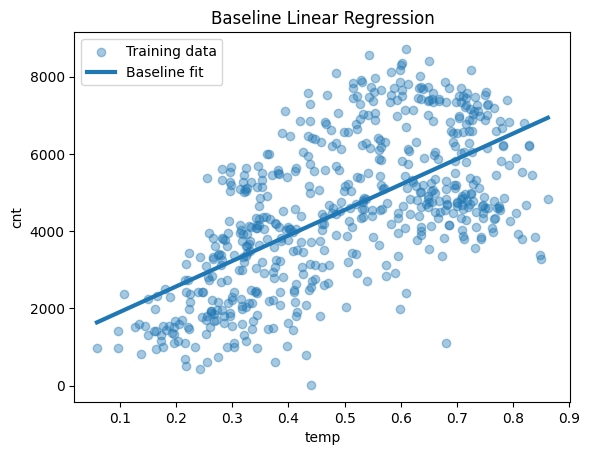

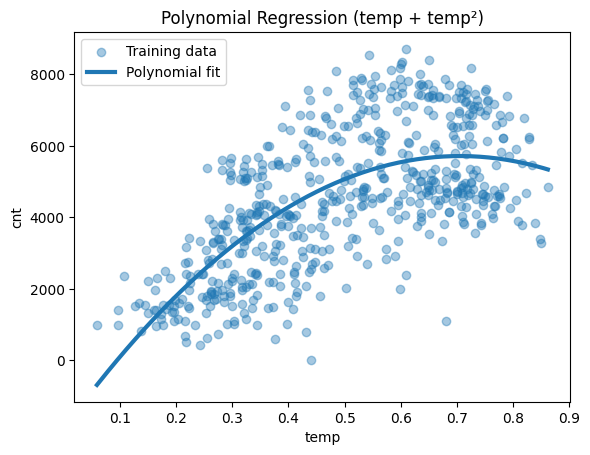

In [43]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()
plt.scatter(X_train_b[:, 0], Y_train, alpha=0.4, label="Training data")
# Base line Plot
temp_range = np.linspace(X_train_b[:, 0].min(),
                         X_train_b[:, 0].max(), 200).reshape(-1, 1)
y_pred_base = model_base.predict(temp_range)
plt.plot(temp_range, y_pred_base, linewidth=3, label="Baseline fit")
plt.xlabel("temp")
plt.ylabel("cnt")
plt.title("Baseline Linear Regression")
plt.legend()
plt.show()
# Temp^2 Plot
plt.figure()
plt.scatter(X_train_b[:, 0], Y_train, alpha=0.4, label="Training data")
temp_range = np.linspace(X_train_b[:, 0].min(),
                         X_train_b[:, 0].max(), 200).reshape(-1, 1)
temp_sq_range = temp_range ** 2
X_poly_range = np.concatenate([temp_range, temp_sq_range], axis=1)
y_pred_poly = model_poly.predict(X_poly_range)
plt.plot(temp_range, y_pred_poly, linewidth=3, label="Polynomial fit")
plt.xlabel("temp")
plt.ylabel("cnt")
plt.title("Polynomial Regression (temp + temp²)")
plt.legend()
plt.show()



## 3.2 Model Retrain Analysis
After retrained the linear regression model using the original feature + two new feature set (polynomial temp^2 and interaction temp*hum), we find that the engineered models achieves a lower MSE than the baseline mode. This indicates that the non-linear feature indeed increase the training performance for the linear regression. 

Between the two newly trained models, the polynomial model(temp^2) seems to have a larger reduction in the MSE, which indicates that the curvature in the relationship between temp and bike rentals plays a more significant role than the temp and humidity. 

While test MSE did not consistently improve, this behavior is expected, as the additional features increase model flexibility and may lead to overfitting. 

Therefore, the results shows how the non-linear transformations are affecting the models' fit and how the traning performance and generalization is infecting each other while trade-off existed in choosing either factor. 